<a href="https://colab.research.google.com/github/mksmk2012/python_projects/blob/main/E-commerce%20Sales%20%26%20Traffic%20Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from scipy.stats import pearsonr
from scipy.stats import wilcoxon
from scipy.stats import shapiro
from scipy.stats import kruskal
from statsmodels.stats.proportion import proportions_ztest
!pip install -q google-cloud-bigquery

In [2]:
from google.colab import auth

auth.authenticate_user()

In [3]:
from google.cloud import bigquery

client = bigquery.Client(project='data-analytics-mate')

In [4]:
query = """
SELECT
      ses.ga_session_id
     ,ses.date
     ,sesp.continent
     ,sesp.country
     ,sesp.device
     ,sesp.browser
     ,sesp.mobile_model_name
     ,sesp.operating_system
     ,sesp.language
     ,sesp.channel
     ,sesp.medium
     ,acc.id
     ,acc.is_verified
     ,acc.is_unsubscribed
     ,prod.category
     ,prod.name
     ,prod.price
     ,prod.short_description
FROM `data-analytics-mate.DA.session` as ses
LEFT JOIN `data-analytics-mate.DA.session_params` as sesp
ON ses.ga_session_id = sesp.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account_session` as acses
ON ses.ga_session_id = acses.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account` as acc
ON acses.account_id = acc.id
LEFT JOIN `data-analytics-mate.DA.order` as ord
ON ses.ga_session_id = ord.ga_session_id
LEFT JOIN `data-analytics-mate.DA.product` as prod
ON ord.item_id = prod.item_id
"""

query_job = client.query(query)

df = query_job.result().to_dataframe(create_bqstorage_client=False)

df.head()

,ga_session_id,date,continent,country,device,browser,mobile_model_name,operating_system,language,channel,medium,id,is_verified,is_unsubscribed,category,name,price,short_description
0,5760483956,2020-11-01,Americas,United States,desktop,Chrome,Safari,Macintosh,zh,Paid Search,<Other>,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,7115337200,2020-11-01,Europe,United Kingdom,desktop,Chrome,Chrome,Web,en-us,Organic Search,organic,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,3978035233,2020-11-01,Europe,Norway,mobile,Chrome,<Other>,Web,zh,Direct,(none),<NA>,<NA>,<NA>,Tables & desks,RÅSKOG,189.0,"Trolley, 35x45x78 cm"
3,9648986282,2020-11-01,Africa,Nigeria,mobile,Chrome,<Other>,Android,es-es,Direct,(none),<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
4,4393441533,2020-11-01,Asia,China,desktop,Chrome,Chrome,Windows,en-us,Direct,(none),<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"


# 1. Initial Data Exploration

## 1.1 Dataset Structure

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   ga_session_id      349545 non-null  Int64  
 1   date               349545 non-null  dbdate 
 2   continent          349545 non-null  object 
 3   country            349545 non-null  object 
 4   device             349545 non-null  object 
 5   browser            349545 non-null  object 
 6   mobile_model_name  349545 non-null  object 
 7   operating_system   349545 non-null  object 
 8   language           235279 non-null  object 
 9   channel            349545 non-null  object 
 10  medium             349545 non-null  object 
 11  id                 27945 non-null   Int64  
 12  is_verified        27945 non-null   Int64  
 13  is_unsubscribed    27945 non-null   Int64  
 14  category           33538 non-null   object 
 15  name               33538 non-null   object 
 16  pr

## 1.2 Unique Sessions

In [6]:
df['ga_session_id'].nunique()

349545

## 1.3 Date Range

In [7]:
df['date'].min(), df['date'].max()

(datetime.date(2020, 11, 1), datetime.date(2021, 1, 31))

## 1.4 Missing Values Analysis

In [8]:
df.isna().mean() * 100

,0
ga_session_id,0.000000
date,0.000000
continent,0.000000
country,0.000000
device,0.000000
browser,0.000000
mobile_model_name,0.000000
operating_system,0.000000
language,32.689925
channel,0.000000


### Dataset Overview

- **Total number of columns:** 18
- **Numerical columns:** 3
- **Binary columns:** 2
- **Categorical columns:** 12
- **Date/Datetime columns:** 1
- **Number of rows:** 349,545
- **Number of unique sessions:** 349,545
- **Date range:** November 1, 2020 – January 31, 2021
- **Missing values:** Yes. The highest proportion of missing values (over 90%) is observed in the id, is_verified, is_unsubscribed, category, name, price, and short_description columns. This is an expected result of using LEFT JOIN: some sessions do not have information about a registered user or an order. Therefore, the corresponding fields contain NULL values.


## 2. Sales and Customer Analysis

### 2.1 Sales by Continent and Country

In [9]:
sales_by_continent = df.groupby('continent')['price'].sum().sort_values(ascending=False)
sales_by_continent.head(3)

,price
continent,
Americas,17665280.0
Asia,7601298.3
Europe,5934624.2


In [10]:
sales_by_country = df.groupby('country')['price'].sum().sort_values(ascending = False)
sales_by_country.head(5)

,price
country,
United States,13943553.9
India,2809762.0
Canada,2437921.0
United Kingdom,938317.9
France,710692.8


The Americas generate the highest total sales, with approximately (17.67M), followed by Asia with (7.60M) and Europe with (5.93M).

At the country level, the United States is the clear leader with approximately  USD 13.94 M in  sales, followed by India (2.81M), Canada (2.44M), the United Kingdom (0.94M), and France (0.71M).

In [11]:
orders_by_continent = (
    df.dropna(subset=['price'])
      .groupby('continent')['ga_session_id']
      .nunique()
      .sort_values(ascending=False)
)

orders_by_continent.head(3)

,ga_session_id
continent,
Americas,18553
Asia,7950
Europe,6261


In [12]:
orders_by_country = (
    df.dropna(subset=['price'])
      .groupby('country')['ga_session_id']
      .nunique()
      .sort_values(ascending=False)
)

orders_by_country.head(5)

,ga_session_id
country,
United States,14673
India,3029
Canada,2560
United Kingdom,1029
France,678


The Americas have the highest number of purchasing sessions (193,179), followed by Asia (83,113) and Europe (65,135).

At the country level, the United States has the highest number of purchasing sessions (14,673), followed by India (3,029), Canada (2,560), the United Kingdom (1,029), and France (678).

The results show that the Americas lead both at the continent level and through the strong contribution of the United States, which has the highest number of purchasing sessions among all countries.

### 2.2 Top Product Categories by Sales


(0.0, 9646492.674999999)

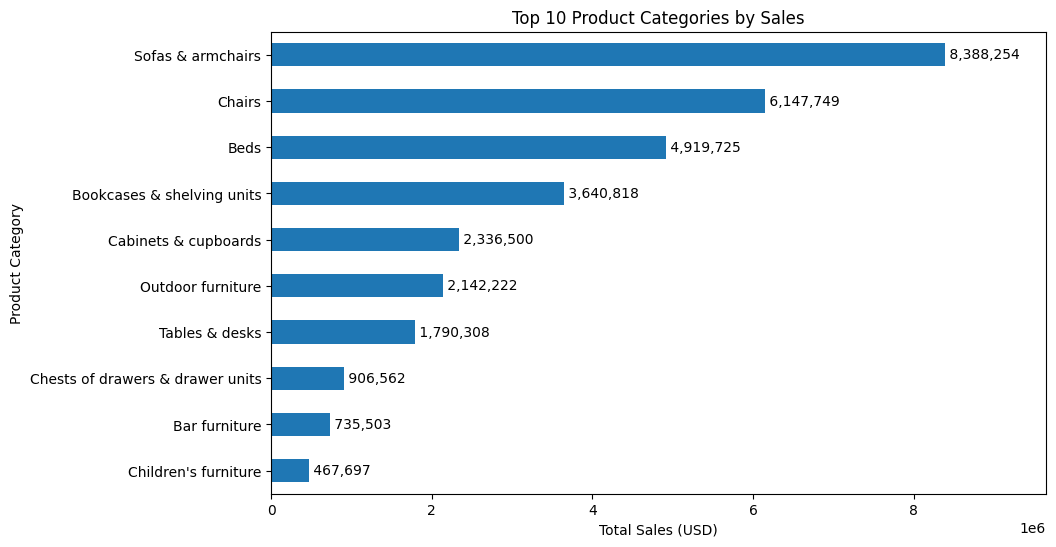

In [13]:
top10_product_by_sales = df.groupby('category')['price'].sum().sort_values(ascending=False)

ax = top10_product_by_sales.head(10).sort_values().plot(
    kind='barh',
    figsize=(10, 6),
    title='Top 10 Product Categories by Sales',
    xlabel='Total Sales (USD)',
    ylabel='Product Category'
)

for i, value in enumerate(top10_product_by_sales.head(10).sort_values()):
    ax.text(value, i, f' {value:,.0f}', va='center')

ax.set_xlim(0, top10_product_by_sales.head(10).max() * 1.15)

The Sofas & armchairs category generates the highest total sales at approximately 8.39M USD, followed by Chairs (6.15M USD) and Beds (4.92M USD).

The remaining top categories include Bookcases & shelving units, Cabinets & cupboards, Outdoor furniture, Tables & desks, Chests of drawers & drawer units, Bar furniture, and Children's furniture.

Overall, the results show that Sofas & armchairs are the leading product category by total sales, with a significant gap compared with the other categories.


### 2.3 Top Categories in the Leading Country

(0.0, 4263216.175)

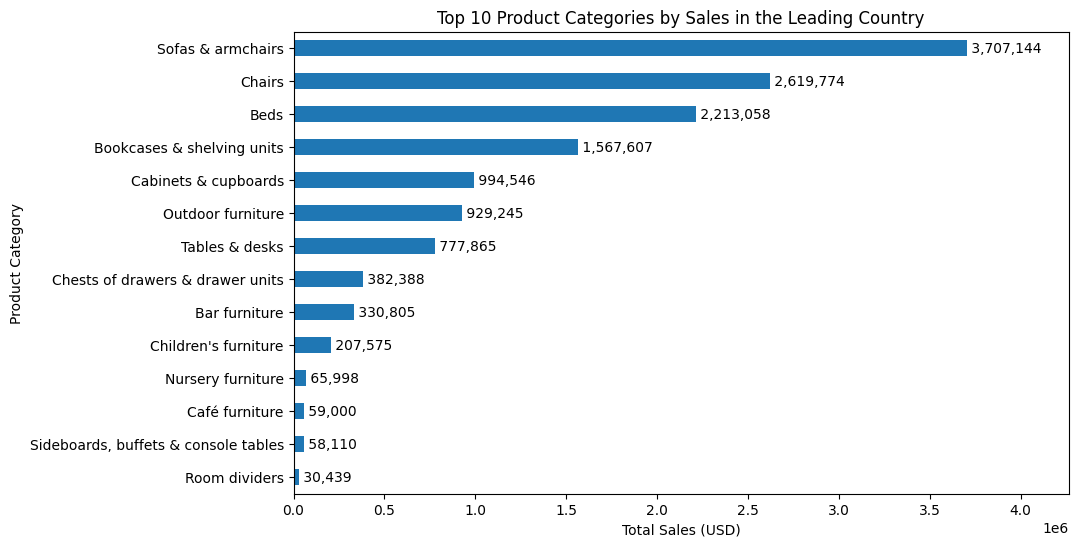

In [14]:
#Find the country with the highest total sales
top_country = df.groupby('country')['price'].sum().idxmax()

# Find the top 10 product categories by sales in the leading country.
top_sales_lead_country = (
    df[df['country'] == top_country]
    .groupby('category')['price']
    .sum()
    .sort_values(ascending=True)
)

# Visualize the top 10 product categories by sales in the leading country.
ax = top_sales_lead_country.plot(
    kind='barh',
    figsize=(10, 6),
    title='Top 10 Product Categories by Sales in the Leading Country',
    xlabel='Total Sales (USD)',
    ylabel='Product Category'
)

for i, value in enumerate(top_sales_lead_country.sort_values()):
    ax.text(value, i, f' {value:,.0f}', va='center')

ax.set_xlim(0, top_sales_lead_country.max() * 1.15)

The United States is the country with the highest total sales. The chart below shows the top 10 product categories by sales in this country.

Sofas & armchairs generate the highest sales, followed by Chairs and Beds. These three categories account for a significant share of sales in the leading country.


### 2.4 Sales by Device Type and model

(0.0, 9967466.768000001)

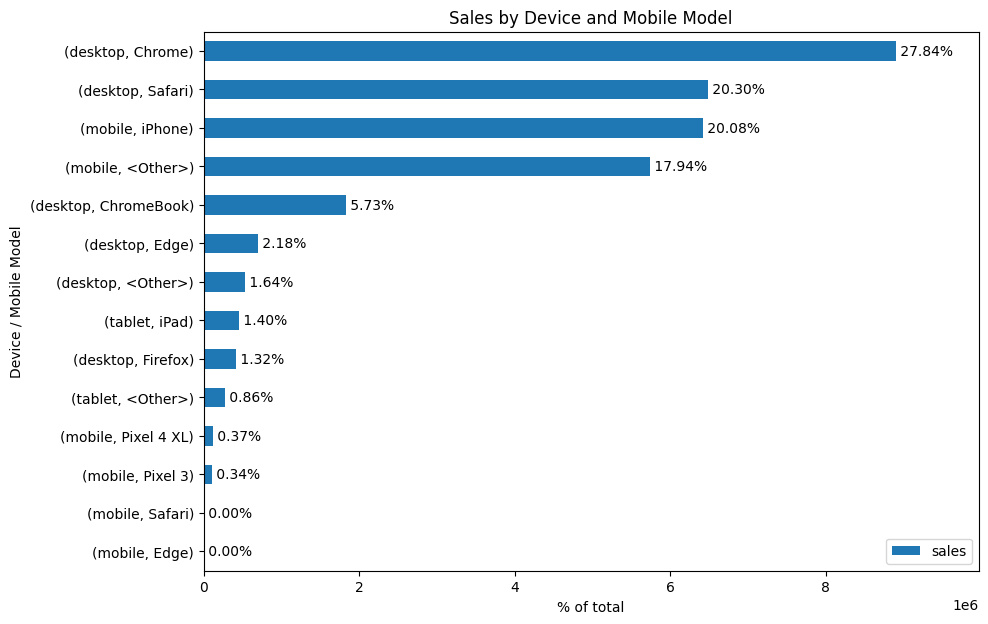

In [15]:
sales_by_device = df.groupby(['device', 'mobile_model_name'])['price'].sum().sort_values(ascending=False)
sales_by_device = sales_by_device.to_frame(name='sales')
sales_by_device['percentage'] = sales_by_device['sales']/sales_by_device['sales'].sum()*100
sales_by_device['percentage'] = sales_by_device['percentage'].round(2)

ax = sales_by_device.sort_values('sales').plot(
    kind='barh',
    y='sales',
    figsize=(10, 7),
    title='Sales by Device and Mobile Model',
    xlabel='% of total',
    ylabel='Device / Mobile Model'
)

for i, (sales, percentage) in enumerate(
    zip(sales_by_device.sort_values('sales')['sales'],
        sales_by_device.sort_values('sales')['percentage'])
):
    ax.text(sales, i, f' {percentage:.2f}%', va='center')

ax.set_xlim(0, sales_by_device['sales'].max() * 1.12)

Sales by Device and Mobile Model

The desktop Chrome segment generates the highest sales, accounting for 27.84% of total sales. It is followed by desktop Safari (20.30%) and mobile iPhone (20.08%).

Other notable segments include mobile <Other> (17.94%) and desktop ChromeBook (5.73%).

Overall, sales are concentrated mainly among desktop Chrome, desktop Safari, and mobile iPhone, which together account for approximately 68% of total sales.


### 2.5 Sales by Traffic Source

(0.0, 15434754.66)

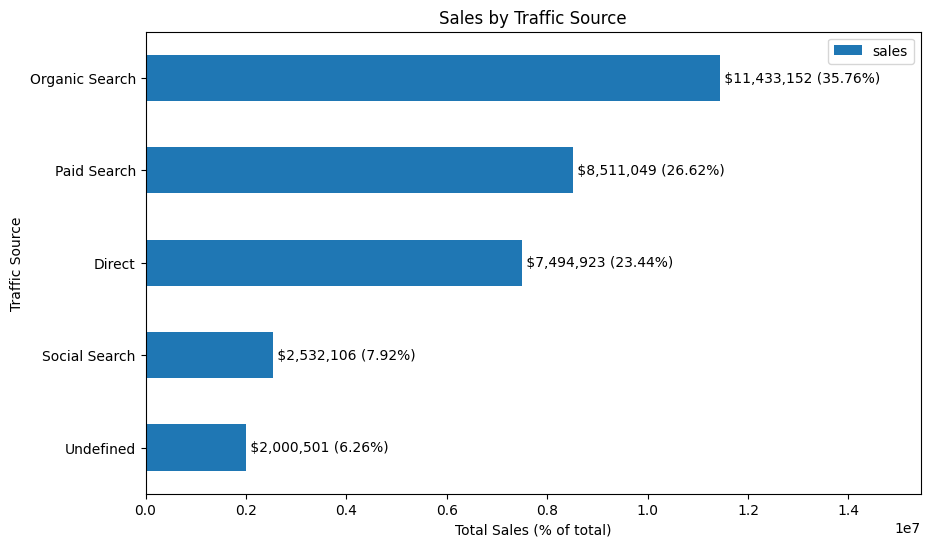

In [16]:
sales_by_traffic = df.groupby('channel')['price'].sum().sort_values(ascending=False)
sales_by_traffic = sales_by_traffic.to_frame(name='sales')
sales_by_traffic['%_of_total'] = sales_by_traffic['sales']/sales_by_traffic['sales'].sum()*100
sales_by_traffic['%_of_total'] = sales_by_traffic['%_of_total'].round(2)

plot_data = sales_by_traffic.sort_values('sales')

ax = plot_data.plot(
    kind='barh',
    y='sales',
    figsize=(10, 6),
    title='Sales by Traffic Source',
    xlabel='Total Sales (% of total)',
    ylabel='Traffic Source'
)

for i, (sales, percentage) in enumerate(
    zip(plot_data['sales'], plot_data['%_of_total'])
):
    ax.text(
        sales,
        i,
        f' ${sales:,.0f} ({percentage:.2f}%)',
        va='center'
    )

ax.set_xlim(0, plot_data['sales'].max() * 1.35)

Organic Search is the largest traffic source, generating approximately 11.43M USD, which accounts for 35.76% of total sales.

Paid Search is the second-largest source with approximately 8.51M USD (26.62%), followed by Direct traffic with 7.49M USD (23.44%).

Together, Organic Search, Paid Search, and Direct traffic account for 85.82% of total sales. Social Search contributes 7.92%, while Undefined accounts for 6.26%.

Overall, the results show that sales are primarily generated through Organic Search, Paid Search, and Direct traffic.

In [17]:
df.head()

,ga_session_id,date,continent,country,device,browser,mobile_model_name,operating_system,language,channel,medium,id,is_verified,is_unsubscribed,category,name,price,short_description
0,5760483956,2020-11-01,Americas,United States,desktop,Chrome,Safari,Macintosh,zh,Paid Search,<Other>,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,7115337200,2020-11-01,Europe,United Kingdom,desktop,Chrome,Chrome,Web,en-us,Organic Search,organic,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,3978035233,2020-11-01,Europe,Norway,mobile,Chrome,<Other>,Web,zh,Direct,(none),<NA>,<NA>,<NA>,Tables & desks,RÅSKOG,189.0,"Trolley, 35x45x78 cm"
3,9648986282,2020-11-01,Africa,Nigeria,mobile,Chrome,<Other>,Android,es-es,Direct,(none),<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
4,4393441533,2020-11-01,Asia,China,desktop,Chrome,Chrome,Windows,en-us,Direct,(none),<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"



### 2.6 Registered Users and Email Verification

In [18]:
registered_users = df.dropna(subset=['id']).drop_duplicates(subset=['id'])
verification_rate = registered_users['is_verified'].sum()/registered_users['is_verified'].count()*100
unsubscribed_rate = registered_users['is_unsubscribed'].sum()/registered_users['is_unsubscribed'].count()*100

print(f'Email verification rate: {verification_rate:.2f}%')
print(f'Email unsubscribe rate: {unsubscribed_rate:.2f}%')

Email verification rate: 71.70%
Email unsubscribe rate: 16.94%


The percentage of registered users who verified their email address is 71.70%.

The percentage of registered users who unsubscribed from the newsletter is 16.94%


### 2.7 Newsletter Subscription Analysis

(0.0, 2473416.4349999996)

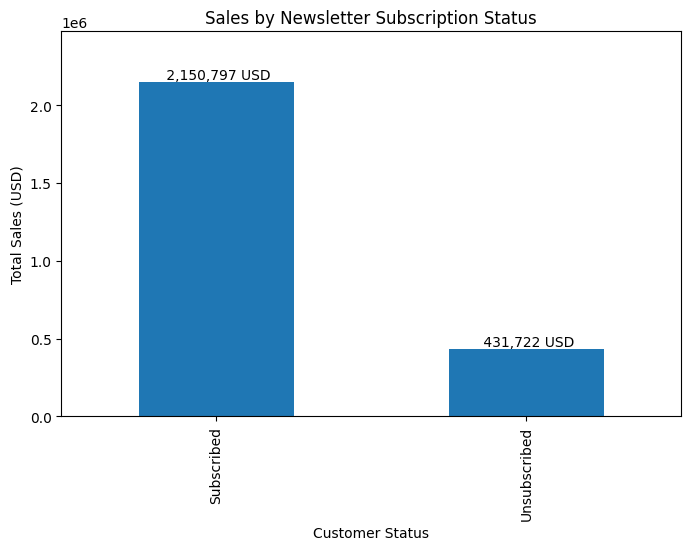

In [19]:
subscribed_sales = df[df['is_unsubscribed'] == 0]['price'].sum()
unsubscribed_sales = df[df['is_unsubscribed'] == 1]['price'].sum()

sales_comparison = pd.Series({
    'Subscribed': subscribed_sales,
    'Unsubscribed': unsubscribed_sales
})

ax = sales_comparison.plot(
    kind='bar',
    figsize=(8, 5),
    title='Sales by Newsletter Subscription Status',
    xlabel='Customer Status',
    ylabel='Total Sales (USD)'
)

for i, value in enumerate(sales_comparison):
    ax.text(i, value, f' {value:,.0f} USD', ha='center', va='bottom')

ax.set_ylim(0, sales_comparison.max() * 1.15)

Subscribed customers generated approximately 2.15M USD in total sales, while unsubscribed customers generated 431.72K USD.

This indicates that the subscribed group generated substantially more sales than the unsubscribed group. However, total sales alone do not show whether subscription status is associated with higher customer spending, as the two groups may differ in size.


### 2.8 Registered Users by Country

(0.0, 14241.599999999999)

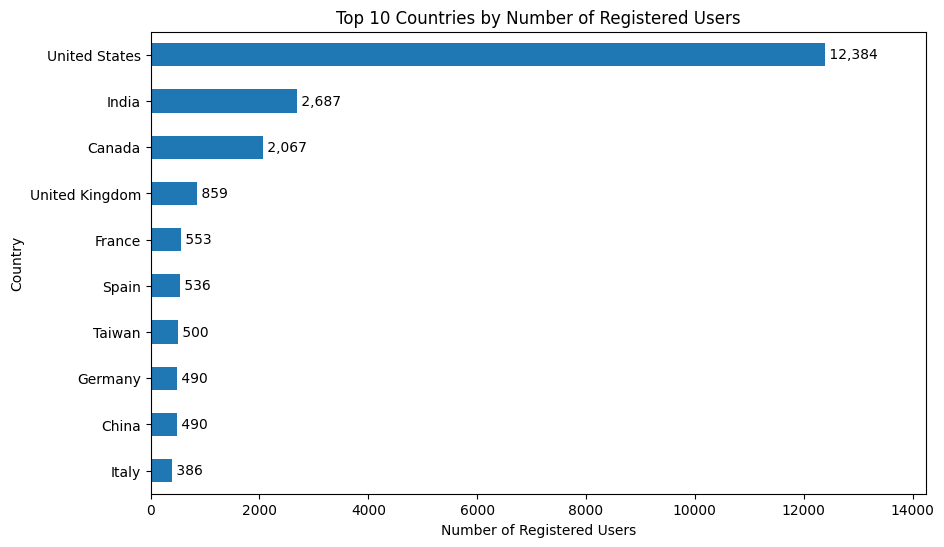

In [20]:
top_registered_country = (
    registered_users.groupby('country')['id']
    .nunique()
    .sort_values(ascending=False)
)

top10_registered_country = top_registered_country.head(10).sort_values()

ax = top10_registered_country.plot(
    kind='barh',
    figsize=(10, 6),
    title='Top 10 Countries by Number of Registered Users',
    xlabel='Number of Registered Users',
    ylabel='Country'
)

for i, value in enumerate(top10_registered_country):
    ax.text(value, i, f' {value:,}', va='center')

ax.set_xlim(0, top10_registered_country.max() * 1.15)

## 3. Sales Dynamics Analysis

###3.1 Overall Sales Dynamics


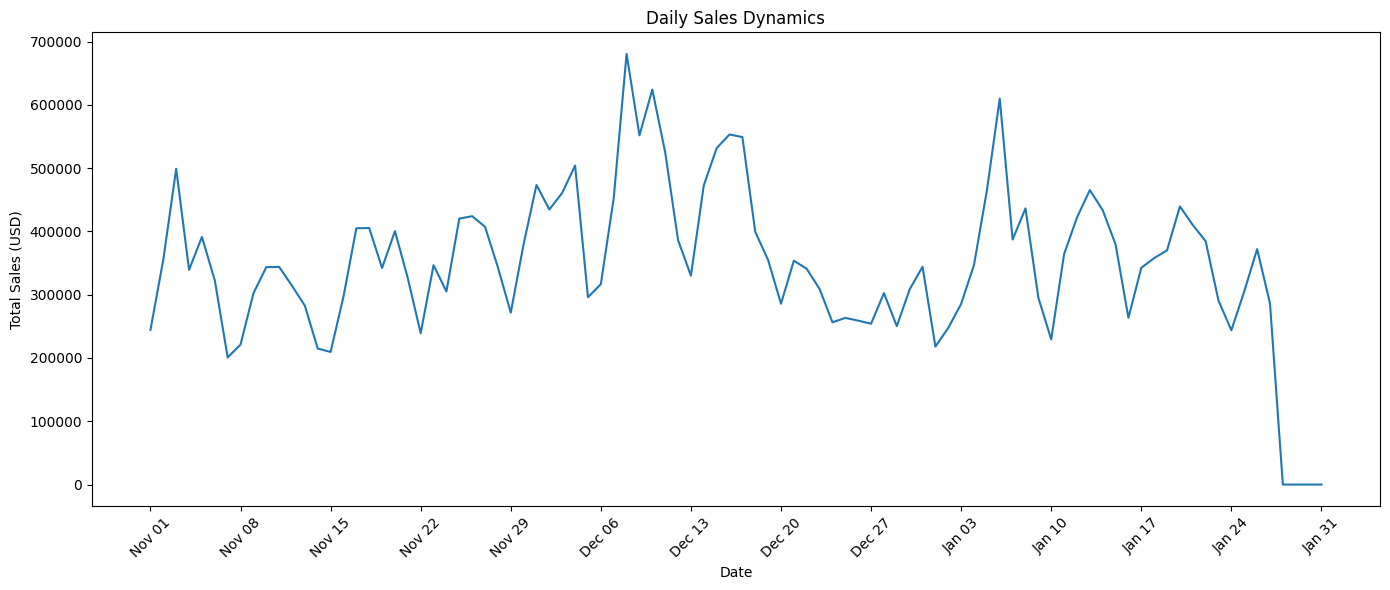

In [21]:
sales_by_date = df.groupby('date')['price'].sum()

ax = sales_by_date.plot(
    kind='line',
    figsize=(14, 6),
    title='Daily Sales Dynamics',
    xlabel='Date',
    ylabel='Total Sales (USD)'
)

ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

plt.xticks(rotation=45)
plt.tight_layout()


Daily sales show considerable fluctuations throughout the analyzed period, with sales generally ranging between 200K and 500K USD per day.

The highest sales peak occurs in early December, reaching approximately 680K USD. Another significant peak appears in early January, at around 610K USD. Several smaller peaks are also observed throughout November and January.

Sales decline noticeably at several points, particularly in mid-November, late December, and late January, with the lowest regular daily values being around 200K–250K USD.

Overall, the sales pattern is volatile rather than steadily increasing or decreasing, with repeated short-term increases and decreases throughout the period.

###3.2 Sales Dynamics by Continent

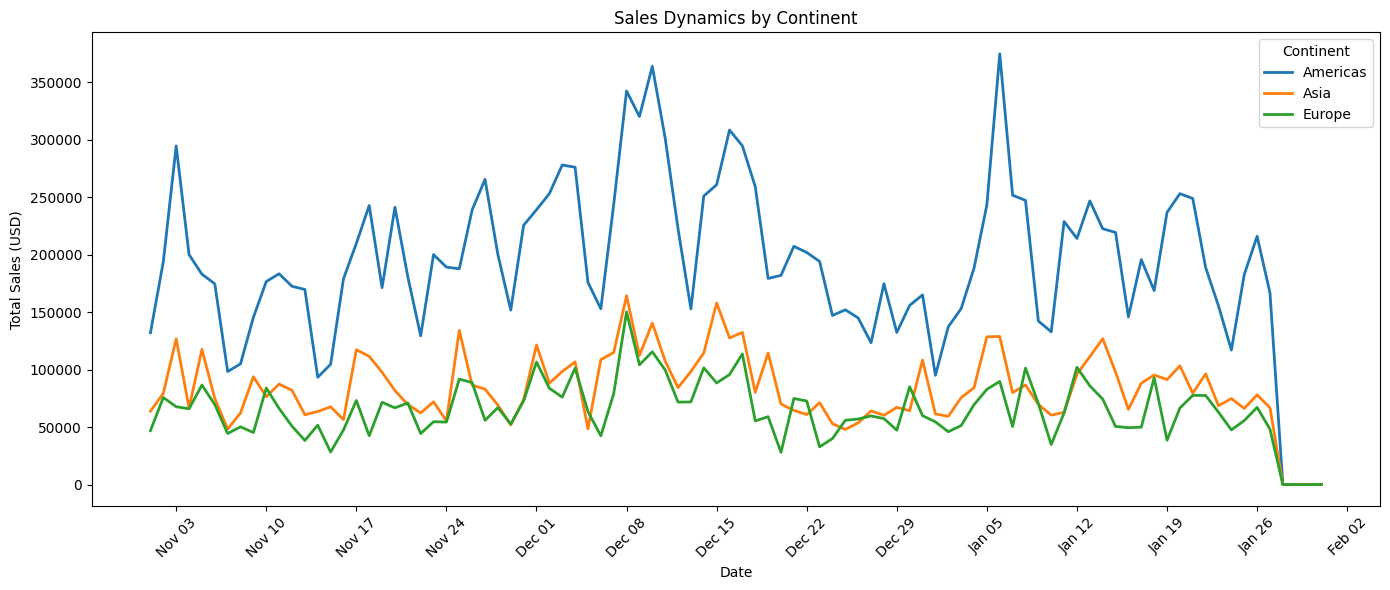

In [22]:
continent_sales_dynamic = df[df['continent'].isin(['Americas', 'Asia', 'Europe'])].groupby(['date', 'continent'])['price'].sum().unstack()

ax = continent_sales_dynamic.plot(
    kind='line',
    figsize=(14, 6),
    title='Sales Dynamics by Continent',
    xlabel='Date',
    ylabel='Total Sales (USD)',
    linewidth=2
)

ax.legend(title='Continent')
ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
plt.xticks(rotation=45)
plt.tight_layout()



Sales dynamics show consistent leadership from the Americas, which maintain the highest values throughout the period with noticeable peaks reaching around 350–380k USD. Asia follows with moderate, steady fluctuations in the mid‑range, while Europe remains the lowest but still demonstrates occasional upward movements. Overall, the trend highlights strong dominance of the Americas and more stable, less volatile performance in Asia and Europe.

###3.3 Sales Dynamics by Traffic Source


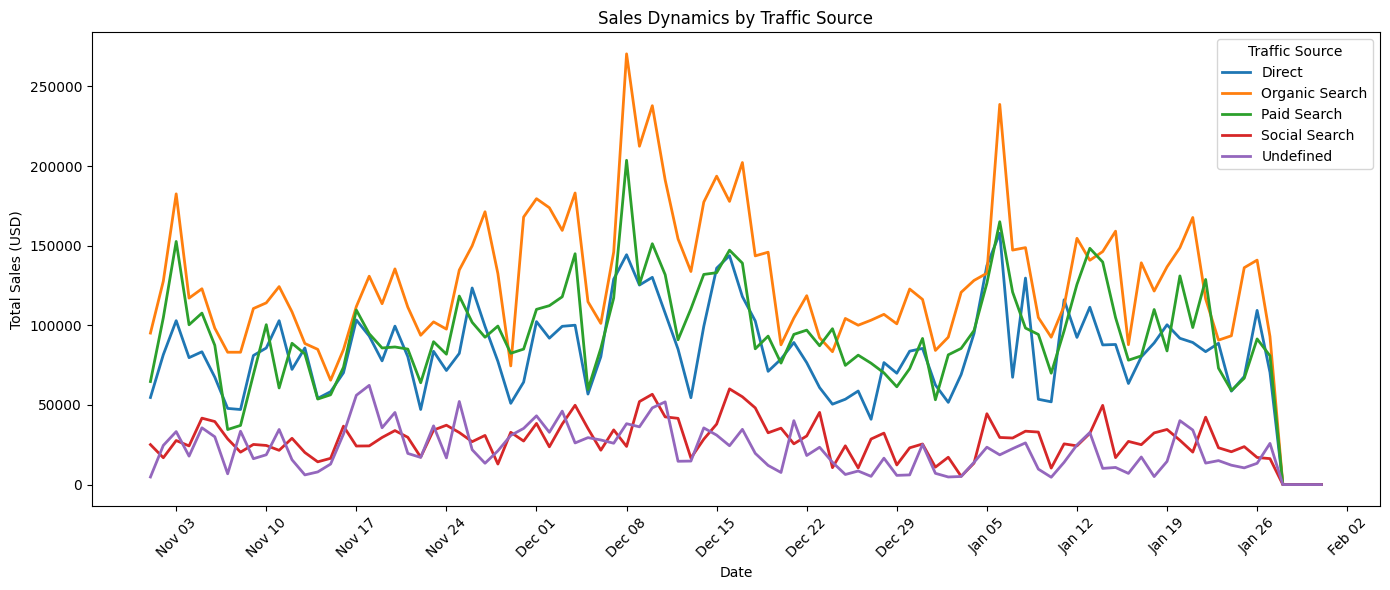

In [23]:
channel_sales_dynamic = df.groupby(['date', 'channel'])['price'].sum().unstack()

ax = channel_sales_dynamic.plot(
    kind='line',
    figsize=(14, 6),
    title='Sales Dynamics by Traffic Source',
    xlabel='Date',
    ylabel='Total Sales (USD)',
    linewidth=2
)

ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

plt.xticks(rotation=45)
plt.legend(title='Traffic Source')
plt.tight_layout()


Sales dynamics vary significantly across traffic sources throughout the analyzed period.

**Organic Search** consistently generates the highest sales and shows several pronounced peaks, particularly in early December and early January. **Paid Search** and **Direct** also contribute substantially to total sales and demonstrate similar short-term fluctuations.

**Social Search** and **Undefined** generate considerably lower sales volumes. Their dynamics are more volatile relative to their overall sales levels, with frequent short-term increases and decreases.

Overall, the sales pattern is highly dynamic across all traffic sources. **Organic Search, Paid Search, and Direct** remain the main contributors to sales throughout the analyzed period, while the other channels generate considerably lower sales volumes.

###3.4 Sales Dynamics by Device Type

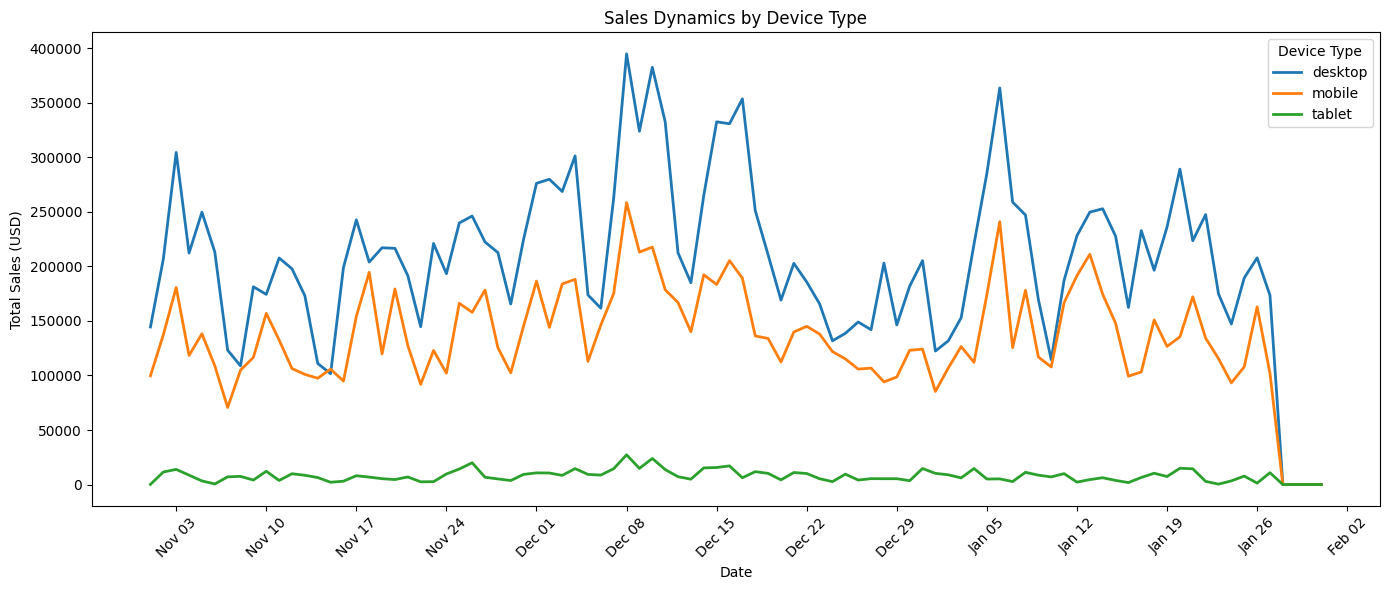

In [24]:
device_sales_dynamic = df.groupby(['date', 'device'])['price'].sum().unstack()

ax = device_sales_dynamic.plot(
    kind='line',
    figsize=(14, 6),
    title='Sales Dynamics by Device Type',
    xlabel='Date',
    ylabel='Total Sales (USD)',
    linewidth=2
)

ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

plt.xticks(rotation=45)
plt.legend(title='Device Type')
plt.tight_layout()

Sales dynamics differ substantially across device types throughout the analyzed period.

**Desktop** generates the highest sales throughout almost the entire period and shows the largest fluctuations, with several significant peaks in December and January. This is consistent with the overall higher sales contribution of desktop users.

**Mobile** is the second-largest device type and follows a similar pattern to desktop, with noticeable increases and decreases throughout the period. However, its sales remain consistently below desktop sales.

**Tablet** generates significantly lower sales compared with desktop and mobile. Its sales remain relatively stable at a much lower level, with only occasional increases.

Overall, **desktop is the dominant device type by sales**, while mobile represents a substantial secondary source of revenue. The dynamics across all device types show frequent short-term fluctuations rather than a consistent upward or downward trend.

##4. Pivot Table Analysis
###4.1 Sessions by Traffic Channel and Device Type


In [25]:
channel_device_sessions_pivot = pd.pivot_table(
    df,
    values='ga_session_id',
    index='channel',
    columns='device',
    aggfunc='count',
    fill_value=0
)
channel_device_sessions_pivot

device,desktop,mobile,tablet
channel,,,
Direct,47825,31745,1812
Organic Search,72622,49014,2789
Paid Search,55167,37034,2140
Social Search,16288,10988,638
Undefined,12527,8486,470


The majority of sessions come from desktop devices across all traffic channels. Organic Search generates the highest number of sessions on both desktop (72,622) and mobile (49,014), indicating that organic search is the main source of traffic regardless of device type. Paid Search also contributes a substantial volume, while Social Search generates considerably fewer sessions.

The device distribution is consistent across channels: desktop leads, followed by mobile and then tablet. This suggests that the difference in traffic volume is driven more by the overall strength of each traffic channel than by major differences in device preferences between channels.

Overall, Organic Search and Paid Search account for the largest traffic volumes, while tablet usage remains relatively limited across all channels. This indicates that desktop and mobile users should be the primary focus when analyzing traffic behavior and engagement.

###4.2 Sales by Product Category and Country

In [26]:
#Find Top-10 product categories by sales
top10_categories = df.groupby('category')['price'].sum().nlargest(10).index

#Find Top-5 countries by sales
top5_countries = df.groupby('country')['price'].sum().nlargest(5).index

#Filter the data and create a Pivot Table
filtered_df = df[df['category'].isin(top10_categories) & df['country'].isin(top5_countries)]

category_country_sales_pivot = pd.pivot_table(
    filtered_df,
    values='price',
    index='category',
    columns='country',
    aggfunc='sum',
    fill_value=0
)

category_country_sales_pivot

country,Canada,France,India,United Kingdom,United States
category,,,,,
Bar furniture,51724.0,11199.0,57657.0,22103.0,330805.0
Beds,354772.0,116414.0,358319.5,133816.0,2213058.0
Bookcases & shelving units,278981.9,73830.0,364507.4,113987.6,1567606.9
Cabinets & cupboards,181802.0,59101.5,191888.0,71684.5,994545.5
Chairs,417740.8,134029.4,544309.2,188519.4,2619773.8
Chests of drawers & drawer units,71952.0,21544.5,73111.0,36784.0,382388.0
Children's furniture,30264.0,14258.0,39177.0,13348.0,207575.0
Outdoor furniture,185322.8,40486.4,162289.4,57002.4,929245.2
Sofas & armchairs,692427.5,187735.0,788430.0,234812.0,3707144.5


The pivot table shows that the United States generates the highest sales across all Top-10 product categories. Sofas & armchairs have the highest sales in the United States (USD 3.71M), followed by Chairs (USD 2.62M) and Beds (USD 2.21M). This indicates that these categories are the main contributors to sales in the largest market.

India and Canada show similar category patterns, with Sofas & armchairs, Chairs, and Beds also generating the highest sales. However, sales volumes are considerably lower than in the United States. France and the United Kingdom have the lowest sales across most categories, although the same leading product categories remain visible.

Overall, Sofas & armchairs and Chairs demonstrate the strongest sales performance across the selected countries, while Children's furniture and Bar furniture generate substantially lower sales. The consistency of the leading categories across countries suggests that these products have broad demand across different markets.

### 4.3 Sessions by Weekday and Device Type

In [27]:
df['weekday'] = pd.to_datetime(df['date']).dt.day_name()

weekday_device_pivot = pd.pivot_table(
    df,
    values='ga_session_id',
    index='weekday',
    columns='device',
    aggfunc='count',
    fill_value=0
)

weekday_device_pivot

device,desktop,mobile,tablet
weekday,,,
Friday,28978,19497,1128
Monday,29253,19668,1148
Saturday,23005,15643,875
Sunday,23265,15591,846
Thursday,31704,21193,1238
Tuesday,34115,23118,1290
Wednesday,34109,22557,1324


Session activity varies noticeably across the week, with the highest traffic occurring on Tuesday and Wednesday. These two days generate almost identical desktop traffic, at 34,115 and 34,109 sessions respectively, while Thursday also shows relatively high activity. In contrast, Saturday and Sunday have the lowest session volumes across all device types.

Desktop consistently accounts for the largest share of sessions on every day, followed by mobile and tablet. The distribution between devices remains relatively stable throughout the week, suggesting that the weekly variation in total traffic is driven primarily by changes in overall session volume rather than major shifts in device usage.

The concentration of sessions during the middle of the week indicates that user activity is stronger on weekdays, particularly Tuesday through Thursday. Weekend traffic is substantially lower, which may reflect differences in users' browsing behavior and purchasing activity between weekdays and weekends.

## 4. Statistical Analysis of Relationships
### 4.1 Correlation Between Daily Sessions and Sales


In [28]:
#calculate the number of unique sessions for each date
daily_sessions = (
    df.groupby('date')['ga_session_id']
      .nunique()
)

#calculate total sales for each date
daily_sales = (
    df.groupby('date')['price']
      .sum()
)

#combine daily sessions and sales into one DataFrame
daily_sessions_sales = pd.concat(
    [daily_sessions, daily_sales],
    axis=1
)

#rename columns for easier interpretation
daily_sessions_sales.columns = ['sessions', 'sales']

daily_sessions_sales.head()

,sessions,sales
date,,
2020-11-01,2576,244292.5
2020-11-02,3599,355506.8
2020-11-03,5173,498979.6
2020-11-04,4184,339187.1
2020-11-05,3743,391276.6


In [29]:
#calculate the Pearson correlation coefficient and p-value
r, p_value = pearsonr(
    daily_sessions_sales['sessions'],
    daily_sessions_sales['sales']
)

print(f'Pearson correlation coefficient: {r:.3f}')
print(f'p-value: {p_value:.4f}')

Pearson correlation coefficient: 0.791
p-value: 0.0000


In [30]:
#check whether the correlation is statistically significant
if p_value < 0.05:
    print('The correlation is statistically significant.')
else:
    print('The correlation is not statistically significant.')

The correlation is statistically significant.


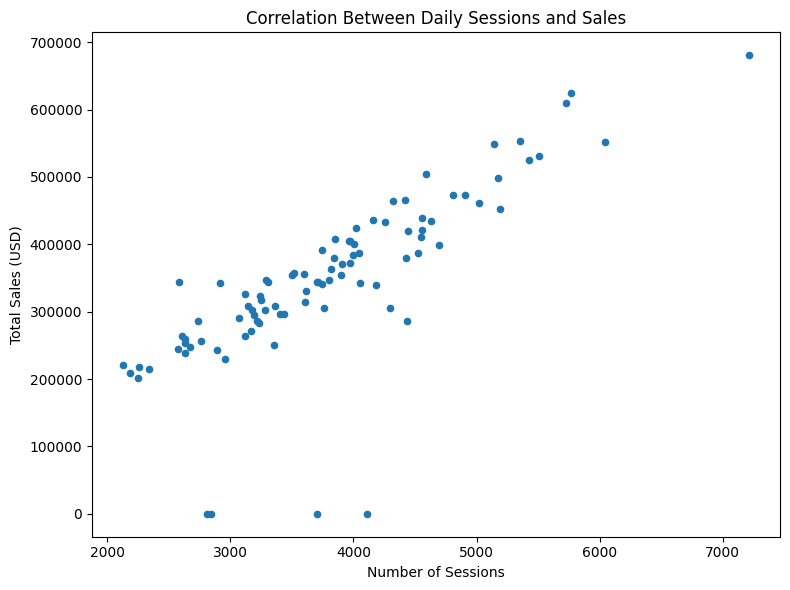

In [31]:
#create a scatter plot to visualize the relationship between sessions and sales
ax = daily_sessions_sales.plot(
    kind='scatter',
    x='sessions',
    y='sales',
    figsize=(8, 6),
    title='Correlation Between Daily Sessions and Sales',
    xlabel='Number of Sessions',
    ylabel='Total Sales (USD)'
)

plt.tight_layout()

The Pearson correlation coefficient between the number of daily sessions and daily sales is 0.791, indicating a strong positive correlation.

The p-value is less than 0.001, which indicates that the correlation is statistically significant at the 5% significance level.

This suggests that days with a higher number of sessions tend to be associated with higher sales. However, correlation does not imply that an increase in sessions directly causes an increase in sales.

### 4.2 Correlation Between Sales Across Top 3 Continents


In [32]:
#identify the top 3 continents by total sales
top3_continents = (
    df.groupby('continent')['price']
      .sum()
      .sort_values(ascending=False)
      .head(3)
)

#calculate daily sales for the top 3 continents
continent_sales_dynamic = (
    df[df['continent'].isin(top3_continents.index)]
    .groupby(['date', 'continent'])['price']
    .sum()
    .unstack()
)

continent_sales_dynamic.head()

continent,Americas,Asia,Europe
date,,,
2020-11-01,132002.5,63823.0,46908.0
2020-11-02,193861.0,79370.0,75710.8
2020-11-03,294529.8,126737.8,67692.0
2020-11-04,200009.5,66602.0,65915.0
2020-11-05,182988.2,117608.4,86540.0


In [33]:
#calculate the correlation matrix between the top 3 continents
continent_correlation = continent_sales_dynamic.corr()

continent_correlation

continent,Americas,Asia,Europe
continent,,,
Americas,1.000000,0.792025,0.770586
Asia,0.792025,1.000000,0.768427
Europe,0.770586,0.768427,1.000000


In [34]:
#test the statistical significance of the correlation between each pair of continents
continents = continent_sales_dynamic.columns

for i in range(len(continents)):
    for j in range(i + 1, len(continents)):

        continent_1 = continents[i]
        continent_2 = continents[j]

#calculate Pearson correlation and p-value for the pair
        r, p_value = pearsonr(
            continent_sales_dynamic[continent_1],
            continent_sales_dynamic[continent_2]
        )

        print(f'{continent_1} vs {continent_2}')
        print(f'Correlation coefficient: {r:.3f}')
        print(f'p-value: {p_value:.4f}')

#check statistical significance at the 5% significance level
        if p_value < 0.05:
            print('Statistically significant correlation')
        else:
            print('Not statistically significant')

print()

Americas vs Asia
Correlation coefficient: 0.792
p-value: 0.0000
Statistically significant correlation
Americas vs Europe
Correlation coefficient: 0.771
p-value: 0.0000
Statistically significant correlation
Asia vs Europe
Correlation coefficient: 0.768
p-value: 0.0000
Statistically significant correlation



Sales across the three largest continents show strong positive correlations.

The correlation between Americas and Asia is 0.792, between Americas and Europe is 0.771, and between Asia and Europe is 0.768. All correlations are statistically significant with p-values below 0.001.

These results indicate that daily sales in the three continents tend to move in the same direction. When sales increase in one continent, sales in the other continents also tend to increase on the same days.

The similar correlation levels suggest that sales across major geographic markets are influenced by common daily or seasonal patterns.


### 4.3 Correlation Between Sales Across Traffic Sources


In [35]:
#calculate daily sales for each traffic source
channel_sales_dynamic = (
    df.groupby(['date', 'channel'])['price']
      .sum()
      .unstack()
)

channel_sales_dynamic.head()

channel,Direct,Organic Search,Paid Search,Social Search,Undefined
date,,,,,
2020-11-01,54669.5,95112.0,64688.0,25078.0,4745.0
2020-11-02,81561.5,127746.5,104780.8,16843.0,24575.0
2020-11-03,102909.5,182521.9,152641.3,27652.5,33254.4
2020-11-04,79683.6,117067.1,100332.0,24257.4,17847.0
2020-11-05,83367.6,122938.4,107648.0,41693.2,35629.4


In [36]:
#calculate the correlation matrix between traffic sources
channel_correlation = channel_sales_dynamic.corr()

channel_correlation

channel,Direct,Organic Search,Paid Search,Social Search,Undefined
channel,,,,,
Direct,1.000000,0.837833,0.814072,0.604060,0.517505
Organic Search,0.837833,1.000000,0.870086,0.583117,0.526068
Paid Search,0.814072,0.870086,1.000000,0.596428,0.521961
Social Search,0.604060,0.583117,0.596428,1.000000,0.455126
Undefined,0.517505,0.526068,0.521961,0.455126,1.000000


In [37]:
#test the statistical significance of the correlation between each pair of traffic sources
channels = channel_sales_dynamic.columns

for i in range(len(channels)):
    for j in range(i + 1, len(channels)):

        channel_1 = channels[i]
        channel_2 = channels[j]

#calculate Pearson correlation and p-value for the pair
        r, p_value = pearsonr(
            channel_sales_dynamic[channel_1],
            channel_sales_dynamic[channel_2]
        )

        print(f'{channel_1} vs {channel_2}')
        print(f'Correlation coefficient: {r:.3f}')
        print(f'p-value: {p_value:.4f}')

#check statistical significance at the 5% significance level
        if p_value < 0.05:
            print('Statistically significant correlation')
        else:
            print('Not statistically significant')

        print()

Direct vs Organic Search
Correlation coefficient: 0.838
p-value: 0.0000
Statistically significant correlation

Direct vs Paid Search
Correlation coefficient: 0.814
p-value: 0.0000
Statistically significant correlation

Direct vs Social Search
Correlation coefficient: 0.604
p-value: 0.0000
Statistically significant correlation

Direct vs Undefined
Correlation coefficient: 0.518
p-value: 0.0000
Statistically significant correlation

Organic Search vs Paid Search
Correlation coefficient: 0.870
p-value: 0.0000
Statistically significant correlation

Organic Search vs Social Search
Correlation coefficient: 0.583
p-value: 0.0000
Statistically significant correlation

Organic Search vs Undefined
Correlation coefficient: 0.526
p-value: 0.0000
Statistically significant correlation

Paid Search vs Social Search
Correlation coefficient: 0.596
p-value: 0.0000
Statistically significant correlation

Paid Search vs Undefined
Correlation coefficient: 0.522
p-value: 0.0000
Statistically significant corr

Sales across all traffic sources show positive and statistically significant correlations.

The strongest correlation is between Organic Search and Paid Search (r = 0.870), followed by Direct and Organic Search (r = 0.838) and Direct and Paid Search (r = 0.814).

The correlations between the smaller traffic sources are also positive but weaker. Social Search and Undefined have the lowest correlation (r = 0.455).

All correlations are statistically significant with p-values below 0.001.

Overall, the results indicate that sales from different traffic sources tend to increase and decrease together. The particularly strong relationships among Organic Search, Paid Search, and Direct traffic suggest similar daily patterns in their sales activity.


### 4.4 Correlation Between Sales Across Top 5 Product Categories


In [38]:
#identify the top 5 product categories by total sales
top5_categories = (
    df.groupby('category')['price']
      .sum()
      .sort_values(ascending=False)
      .head(5)
)

top5_categories

,price
category,
Sofas & armchairs,8388254.5
Chairs,6147748.8
Beds,4919725.0
Bookcases & shelving units,3640818.1
Cabinets & cupboards,2336499.5


In [39]:
#calculate daily sales for the top 5 product categories
category_sales_dynamic = (
    df[df['category'].isin(top5_categories.index)]
    .groupby(['date', 'category'])['price']
    .sum()
    .unstack()
)

category_sales_dynamic.head()

category,Beds,Bookcases & shelving units,Cabinets & cupboards,Chairs,Sofas & armchairs
date,,,,,
2020-11-01,14041.0,36701.0,13591.5,46006.0,75216.0
2020-11-02,79683.5,40979.0,21623.0,58834.0,79977.5
2020-11-03,66219.5,64360.1,33555.5,61204.0,175594.0
2020-11-04,48939.0,35719.8,19266.0,44113.0,86861.5
2020-11-05,23449.0,40998.8,29235.0,90388.4,137288.0


In [40]:
#calculate the correlation matrix between the top 5 product categories
category_correlation = category_sales_dynamic.corr()

category_correlation

category,Beds,Bookcases & shelving units,Cabinets & cupboards,Chairs,Sofas & armchairs
category,,,,,
Beds,1.000000,0.592913,0.514609,0.554500,0.535378
Bookcases & shelving units,0.592913,1.000000,0.539428,0.637090,0.666194
Cabinets & cupboards,0.514609,0.539428,1.000000,0.572870,0.657563
Chairs,0.554500,0.637090,0.572870,1.000000,0.578248
Sofas & armchairs,0.535378,0.666194,0.657563,0.578248,1.000000


In [41]:
#test the statistical significance of the correlation between each pair of categories
categories = category_sales_dynamic.columns

for i in range(len(categories)):
    for j in range(i + 1, len(categories)):

        category_1 = categories[i]
        category_2 = categories[j]

        #calculate Pearson correlation and p-value for the pair
        r, p_value = pearsonr(
            category_sales_dynamic[category_1],
            category_sales_dynamic[category_2]
        )

        print(f'{category_1} vs {category_2}')
        print(f'Correlation coefficient: {r:.3f}')
        print(f'p-value: {p_value:.4f}')

        #check statistical significance at the 5% significance level
        if p_value < 0.05:
            print('Statistically significant correlation')
        else:
            print('Not statistically significant')

        print()

Beds vs Bookcases & shelving units
Correlation coefficient: 0.593
p-value: 0.0000
Statistically significant correlation

Beds vs Cabinets & cupboards
Correlation coefficient: 0.515
p-value: 0.0000
Statistically significant correlation

Beds vs Chairs
Correlation coefficient: 0.554
p-value: 0.0000
Statistically significant correlation

Beds vs Sofas & armchairs
Correlation coefficient: 0.535
p-value: 0.0000
Statistically significant correlation

Bookcases & shelving units vs Cabinets & cupboards
Correlation coefficient: 0.539
p-value: 0.0000
Statistically significant correlation

Bookcases & shelving units vs Chairs
Correlation coefficient: 0.637
p-value: 0.0000
Statistically significant correlation

Bookcases & shelving units vs Sofas & armchairs
Correlation coefficient: 0.666
p-value: 0.0000
Statistically significant correlation

Cabinets & cupboards vs Chairs
Correlation coefficient: 0.573
p-value: 0.0000
Statistically significant correlation

Cabinets & cupboards vs Sofas & armchair

Sales across the top five product categories show moderate positive correlations.

The strongest relationship is between Bookcases & shelving units and Sofas & armchairs (r = 0.666), followed by Cabinets & cupboards and Sofas & armchairs (r = 0.658) and Bookcases & shelving units and Chairs (r = 0.637).

The weakest correlation is between Beds and Cabinets & cupboards (r = 0.515).

All correlations are statistically significant with p-values below 0.001.

These results indicate that sales across the main product categories tend to follow similar daily patterns, although the relationships are not as strong as those observed between some traffic sources or device types.


### 4.5 Correlation Between Sales Across Device Types


In [42]:
#сalculate daily sales for each device type
device_sales_dynamic = (
    df.groupby(['date', 'device'])['price']
      .sum()
      .unstack()
)

device_sales_dynamic.head()

device,desktop,mobile,tablet
date,,,
2020-11-01,144445.0,99698.5,149.0
2020-11-02,206727.3,137269.5,11510.0
2020-11-03,304473.8,180602.8,13903.0
2020-11-04,212227.7,118324.4,8635.0
2020-11-05,249682.0,138256.0,3338.6


In [43]:
#сalculate the correlation matrix between device types
device_correlation = device_sales_dynamic.corr()

device_correlation

device,desktop,mobile,tablet
device,,,
desktop,1.000000,0.873201,0.601354
mobile,0.873201,1.000000,0.567394
tablet,0.601354,0.567394,1.000000


In [44]:
#test the statistical significance of the correlation between each pair of devices
devices = device_sales_dynamic.columns

for i in range(len(devices)):
    for j in range(i + 1, len(devices)):

        device_1 = devices[i]
        device_2 = devices[j]

        #calculate Pearson correlation and p-value for the pair
        r, p_value = pearsonr(
            device_sales_dynamic[device_1],
            device_sales_dynamic[device_2]
        )

        print(f'{device_1} vs {device_2}')
        print(f'Correlation coefficient: {r:.3f}')
        print(f'p-value: {p_value:.4f}')

        #check statistical significance at the 5% significance level
        if p_value < 0.05:
            print('Statistically significant correlation')
        else:
            print('Not statistically significant')

        print()

desktop vs mobile
Correlation coefficient: 0.873
p-value: 0.0000
Statistically significant correlation

desktop vs tablet
Correlation coefficient: 0.601
p-value: 0.0000
Statistically significant correlation

mobile vs tablet
Correlation coefficient: 0.567
p-value: 0.0000
Statistically significant correlation



Sales across all three device types show positive and statistically significant correlations.

The strongest correlation is between desktop and mobile sales (r = 0.873). The correlation between desktop and tablet is 0.601, while mobile and tablet have a correlation of 0.567

All correlations have p-values below 0.001, indicating statistical significance at the 5% significance level.

The strong correlation between desktop and mobile sales suggests that their daily sales patterns tend to move closely together. The weaker correlations involving tablet sales indicate that tablet sales follow the overall pattern less closely.

## 5. Statistical Analysis of Differences Between Groups

### 5.1 Sales: Registered vs. Unregistered Users

In [45]:
df['date'] = pd.to_datetime(df['date'])

#create registered and unregistered user groups
registered = df[df['is_verified'].notna()]
unregistered = df[df['is_verified'].isna()]

#calculate daily sales for each group
registered_daily_sales = registered.groupby('date')['price'].sum()

unregistered_daily_sales = unregistered.groupby('date')['price'].sum()

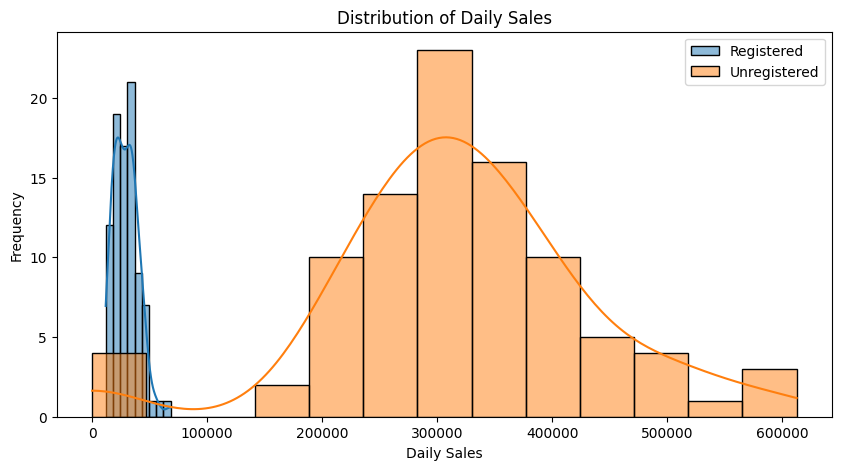

In [46]:
plt.figure(figsize=(10, 5))

sns.histplot(registered_daily_sales, kde=True, label='Registered')
sns.histplot(unregistered_daily_sales, kde=True, label='Unregistered')

plt.xlabel('Daily Sales')
plt.ylabel('Frequency')
plt.title('Distribution of Daily Sales')
plt.legend()
plt.show()

In [47]:
stat_registered, p_registered = shapiro(registered_daily_sales)
stat_unregistered, p_unregistered = shapiro(unregistered_daily_sales)

print(f"Registered: p-value = {p_registered:.4f}")
print(f"Unregistered: p-value = {p_unregistered:.4f}")

Registered: p-value = 0.0073
Unregistered: p-value = 0.0012


In [48]:
from scipy.stats import mannwhitneyu

statistic, p_value = mannwhitneyu(
    registered_daily_sales,
    unregistered_daily_sales,
    alternative='two-sided'
)

print(f'Mann-Whitney U statistic = {statistic:.2f}')
print(f'p-value = {p_value:.4f}')

Mann-Whitney U statistic = 352.00
p-value = 0.0000


In [49]:
alpha = 0.05

if p_value < alpha:
    print('The difference in daily sales between registered and unregistered users is statistically significant.')
else:
    print('There is no statistically significant difference in daily sales between registered and unregistered users.')

The difference in daily sales between registered and unregistered users is statistically significant.


**Hypotheses:**

- **H₀:** The distributions of daily sales of registered and unregistered users are the same.
- **H₁:** The distributions of daily sales of registered and unregistered users differ (two-sided).

**Results:**

- **Mann-Whitney U statistic:** 352.00
- **p-value:** < 0.0001
- **Significance level:** α = 0.05

Since the p-value is far below α = 0.05, we **reject the null hypothesis**. The difference in daily sales between registered and unregistered users is **statistically significant**.

The distribution plot shows the direction and size of the difference:

- Daily sales of **registered users** are concentrated at low values, mostly below roughly \$50K per day.
- Daily sales of **unregistered users** are much higher, typically between \$200K and \$450K per day, with a peak around \$300K and some days reaching about \$600K.
- The two distributions barely overlap, so unregistered users generate far more daily sales than registered users.


### 5.2 Sessions Across Traffic Channels


In [50]:
#calculate the number of sessions by traffic channel
sessions_by_channel = df.groupby('channel')['ga_session_id'].nunique().sort_values(ascending=False)

print(sessions_by_channel)

channel
Organic Search    124425
Paid Search        94341
Direct             81382
Social Search      27914
Undefined          21483
Name: ga_session_id, dtype: int64


In [51]:
#calculate daily sessions for each traffic channel
daily_sessions = df.groupby(['date', 'channel'])['ga_session_id'].nunique().reset_index(name='sessions')

daily_sessions.head()

,date,channel,sessions
0,2020-11-01,Direct,608
1,2020-11-01,Organic Search,920
2,2020-11-01,Paid Search,706
3,2020-11-01,Social Search,214
4,2020-11-01,Undefined,128


In [52]:
daily_sessions.groupby('channel')['sessions'].describe()

,count,mean,std,min,25%,50%,75%,max
channel,,,,,,,,
Direct,92.0,884.586957,220.225267,481.0,744.00,869.5,1004.75,1668.0
Organic Search,92.0,1352.445652,336.572261,733.0,1117.25,1329.0,1558.75,2589.0
Paid Search,92.0,1025.445652,254.421100,578.0,860.25,989.0,1171.75,1959.0
Social Search,92.0,303.413043,88.127923,137.0,235.50,308.0,358.25,561.0
Undefined,92.0,233.510870,83.634276,86.0,160.75,229.0,293.25,435.0


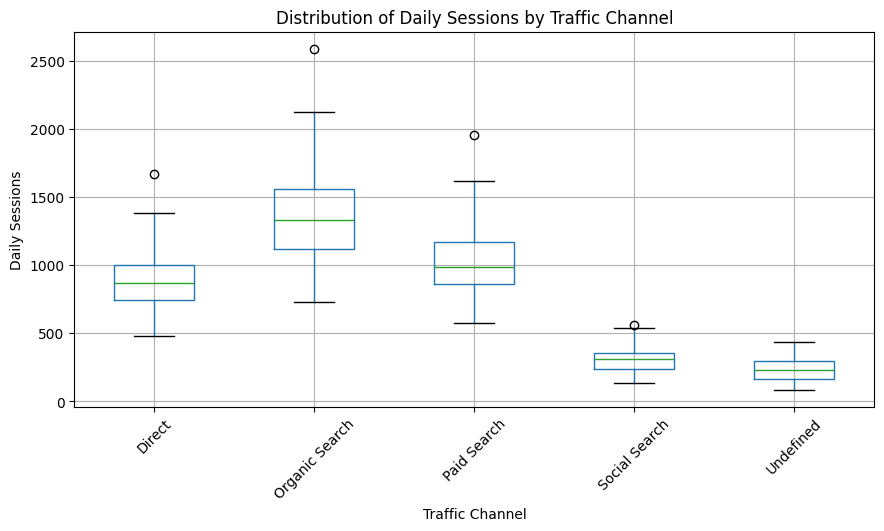

In [53]:
daily_sessions.boxplot(
    column='sessions',
    by='channel',
    figsize=(10, 5)
)

plt.title('Distribution of Daily Sessions by Traffic Channel')
plt.suptitle('')
plt.xlabel('Traffic Channel')
plt.ylabel('Daily Sessions')
plt.xticks(rotation=45)
plt.show()

In [54]:
#create a separate sample for each traffic channel
channel_samples = [
    group['sessions'].values
    for _, group in daily_sessions.groupby('channel')
]

#compare session distributions across all channels
stat, p_value = kruskal(*channel_samples)

print('Kruskal–Wallis statistic:', stat)
print('p-value:', p_value)

Kruskal–Wallis statistic: 368.98057369864847
p-value: 1.397036102599359e-78


In [55]:
alpha = 0.05

if p_value < alpha:
    print(
        'There is a statistically significant difference '
        'in the number of daily sessions between traffic channels.'
    )
else:
    print(
        'There is no statistically significant difference '
        'in the number of daily sessions between traffic channels.'
    )

There is a statistically significant difference in the number of daily sessions between traffic channels.


**Hypotheses:**

- **H₀:** The distributions of daily sessions are the same across all traffic channels.
- **H₁:** At least one traffic channel differs from the others in the distribution of daily sessions.

**Results:**

- **Test statistic:** H = 368.98
- **p-value:** p=1.4e-78
- **Significance level:** α = 0.05

Since the p-value is far below α = 0.05, we reject the null hypothesis. There is a statistically significant difference in the number of daily sessions between traffic channels.

The descriptive statistics and the boxplot show the nature of these differences:

- **Organic Search** has the highest number of daily sessions (mean ≈ 1,350), followed by **Paid Search** (≈ 1,025) and **Direct** (≈ 865).
- **Social Search** (≈ 300) and **Undefined** (≈ 235) generate far fewer sessions per day.
- The variability also differs: the largest channels have a wider spread (std ≈ 240–340), while the smallest are much more stable (std ≈ 70–85).


### 5.3 Share of Organic Traffic Sessions: Europe vs. Americas

In [56]:
#count unique sessions for each continent
total_sessions = df[df['continent'].isin(['Europe', 'Americas'])].groupby('continent')['ga_session_id'].nunique()

#count organic search sessions for each continent
organic_sessions = (
    df[
        (df['continent'].isin(['Europe', 'Americas'])) &
        (df['channel'] == 'Organic Search')
    ]
    .groupby('continent')['ga_session_id'].nunique()
)

#calculate the share of organic sessions
organic_share = organic_sessions / total_sessions

print('Total sessions:')
print(total_sessions)

print('\nOrganic sessions:')
print(organic_sessions)

print('\nOrganic session share:')
print(organic_share)

Total sessions:
continent
Americas    193179
Europe       65135
Name: ga_session_id, dtype: int64

Organic sessions:
continent
Americas    68671
Europe      23195
Name: ga_session_id, dtype: int64

Organic session share:
continent
Americas    0.355479
Europe      0.356107
Name: ga_session_id, dtype: float64


In [57]:
count = [
    organic_sessions['Europe'],
    organic_sessions['Americas']
]

nobs = [
    total_sessions['Europe'],
    total_sessions['Americas']
]

z_stat, p_value = proportions_ztest(
    count=count,
    nobs=nobs
)

print('Z-statistic:', z_stat)
print('p-value:', p_value)

Z-statistic: 0.28951412926103953
p-value: 0.7721879690501752


In [58]:
alpha = 0.05

if p_value < alpha:
    print(
        'There is a statistically significant difference '
        'in the share of organic sessions between Europe and the Americas.'
    )
else:
    print(
        'There is no statistically significant difference '
        'in the share of organic sessions between Europe and the Americas.'
    )

There is no statistically significant difference in the share of organic sessions between Europe and the Americas.


**Hypotheses:**

- **H₀:** The share of organic sessions in Europe is equal to that in the Americas (p₁ = p₂).
- **H₁:** The share of organic sessions in Europe differs from that in the Americas (p₁ ≠ p₂).

**Results:**

- **Z-statistic:** ≈ 0.290
- **p-value:** ≈ 0.772
- **Significance level:** α = 0.05

Since the p-value (0.772) is much greater than α = 0.05, we fail to reject the null hypothesis. There is no statistically significant difference in the share of organic search sessions between Europe and the Americas.

The observed shares are almost identical: about 35.6% in Europe versus 35.5% in the Americas, a difference of roughly 0.06 percentage points. This is notable given the large sample sizes, which would allow even a small difference to be detected. It suggests that organic search contributes a similar portion of traffic in both regions, and that any regional differences in overall sales are not driven by a different reliance on organic search.

# 6. Business Conclusions & Recommendations

## 6.1 Key Business Conclusions

**1. The Americas are the primary sales market.**
The region generated approximately **\$17.67M** in sales, followed by Asia (**\$7.60M**) and Europe (**\$5.93M**). The United States was the leading country, generating approximately **\$13.94M** in sales and the highest number of purchasing sessions among individual countries.

**2. Sales are concentrated in a small number of product categories.**
Sofas & armchairs generated the highest sales at approximately **\$8.39M**, followed by Chairs (**\$6.15M**) and Beds (**\$4.92M**). These categories also consistently lead sales across the major countries analyzed.

**3. Organic Search is the largest sales-generating traffic source.**
Organic Search generated approximately **\$11.43M (35.76%)** of total sales, followed by Paid Search at **\$8.51M (26.62%)** and Direct traffic at **\$7.49M (23.44%)**. Together, these three channels accounted for **85.82%** of total sales.

**4. Desktop and mobile are the primary revenue-generating devices.**
Desktop Chrome generated **27.84%** of total sales, followed by Desktop Safari (**20.30%**) and mobile iPhone (**20.08%**). Desktop and mobile sales also showed a strong positive daily correlation (`r = 0.873`, `p < 0.001`).

**5. Sales and traffic volume are strongly related.**
Daily sessions and daily sales have a strong positive correlation (`r = 0.791`, `p < 0.001`). This means that days with higher session volumes tend to have higher sales. However, correlation does not establish a causal relationship between traffic and sales.

**6. Sales demonstrate significant short-term fluctuations.**
Daily sales generally ranged between **\$200K and \$500K**, with major peaks of approximately **\$680K** in early December and **\$610K** in early January. This indicates substantial short-term variation and possible seasonal effects.

**7. Sales across major markets and traffic sources tend to move together.**
The three largest regions show strong positive correlations in daily sales, while Organic Search, Paid Search, and Direct traffic also demonstrate strong positive relationships. These patterns may indicate common seasonal or market-wide factors affecting sales.

**8. Newsletter subscribers generate more total sales, but this does not necessarily mean they spend more per customer.**
Subscribed customers generated approximately **\$2.15M**, compared with **\$431.72K** from unsubscribed customers. However, the groups may differ substantially in size, so customer-level metrics such as Sales per Customer, Conversion Rate, and AOV should be analyzed before evaluating customer value.

**9. Customer activity is higher during weekdays.**
Tuesday and Wednesday have the highest session volumes, while Saturday and Sunday have the lowest. Desktop remains the dominant device across all days.





## 6.2 Business Recommendations

### 1. Prioritize the United States and other high-performing markets

The United States represents the largest individual market and contributes substantially to overall sales.

The business should consider:

- maintaining sufficient inventory for high-demand products;
- analyzing customer behavior separately for the US market;
- optimizing marketing campaigns for the highest-performing regions;
- comparing conversion rates and customer value across countries before expanding investment into lower-volume markets.

### 2. Focus product strategy on high-performing categories

Sofas & armchairs, Chairs, and Beds are the leading product categories.

The business could use these categories to:

- build promotional campaigns;
- create product bundles;
- develop cross-selling opportunities;
- maintain appropriate inventory levels;
- test recommendations for complementary products.

> Lower-performing categories should not automatically be discontinued. Their margin, conversion rate, AOV, and strategic role should be evaluated first.

### 3. Continue investing in Organic and Paid Search

Organic Search, Paid Search, and Direct traffic account for the majority of sales.

The business should monitor:

- **Organic Search:** traffic, rankings, landing-page performance, and conversion rate;
- **Paid Search:** advertising spend, conversion rate, CAC, and ROAS;
- **Direct traffic:** returning customer behavior and brand-related demand.

The objective should be to evaluate not only sales volume but also the efficiency and profitability of each channel.

### 4. Optimize both desktop and mobile experiences

Desktop is the largest sales-generating device, while mobile represents a substantial secondary source of revenue.

The business should separately monitor the desktop and mobile funnels, including:

`Product page → Add to cart → Checkout → Purchase`

Particular attention should be given to mobile usability, page performance, navigation, and checkout abandonment.

### 5. Use weekday patterns in marketing planning

Traffic is highest during the middle of the week, particularly Tuesday through Thursday, while weekend activity is substantially lower.

The business could test whether campaigns, promotions, and email communications perform better when launched or intensified during high-traffic periods.

This should be validated through conversion rate and revenue analysis, rather than relying only on session volume.

### 6. Investigate the drivers of major sales peaks

The significant sales peaks observed in early December and early January should be investigated against:

- promotional campaigns;
- advertising spend;
- traffic volume;
- conversion rate;
- product availability;
- seasonal demand.

Understanding the drivers of these peaks could help the business replicate successful conditions while avoiding conclusions based solely on observed correlation.

### 7. Improve customer-level analysis

The current analysis shows that newsletter subscribers generate substantially more total sales, but total sales alone cannot determine whether subscribers are more valuable customers.

The next analysis should compare:

- Sales per Customer
- Average Order Value (AOV)
- Purchase Frequency
- Customer Purchase Rate
- Conversion Rate
- Customer Retention

This would provide a more accurate understanding of customer value and help evaluate the potential impact of newsletter engagement.


## 6.3 Overall Business Takeaway

The analysis shows that business performance is concentrated around a few key markets, product categories, traffic sources, and device segments.

The largest opportunities for business improvement are therefore to:

- strengthen performance in the United States and other high-value markets;
- prioritize high-performing product categories;
- optimize Organic Search, Paid Search, and Direct traffic;
- improve the desktop and mobile purchasing experience;
- use customer-level metrics to evaluate customer value;
- investigate seasonal and short-term sales patterns to improve marketing and inventory planning.

[Sales & Customer Performance Dashboard](https://public.tableau.com/views/Book2_17906375676700/SalesDashboard)